In [1]:
import sys, os
sys.path.append(os.path.abspath('..'))

import numpy as np
import matplotlib.pyplot as plt

from models.qutip_model import QutipFermiHubbard
from models.qilisdk_model import QilisdkFermiHubbard

In [ ]:
backend = 'qilisdk'  # 'qutip' or 'qilisdk'

chain_length = 5
gx = 1
gz = 1
e = 2*gz
T = 10.0
dt = 0.05



nsteps = int(T/dt) -1
model_qutip = QutipFermiHubbard(chain_length, gx, gz, e, T, nsteps)
model_qutip.place_single_excitation('up', 0)
model_qutip.place_single_excitation('down', chain_length-1)

dt = dt
model_qilisdk = QilisdkFermiHubbard(chain_length, gx, gz, e, T, dt)
model_qilisdk.place_single_excitation('up', 0)
model_qilisdk.place_single_excitation('down', chain_length-1)

result_qutip, expectation_values_qutip = model_qutip.run()
result_qilisdk, expectation_values_qilisdk = model_qilisdk.run()

ValueError: too many values to unpack (expected 2)

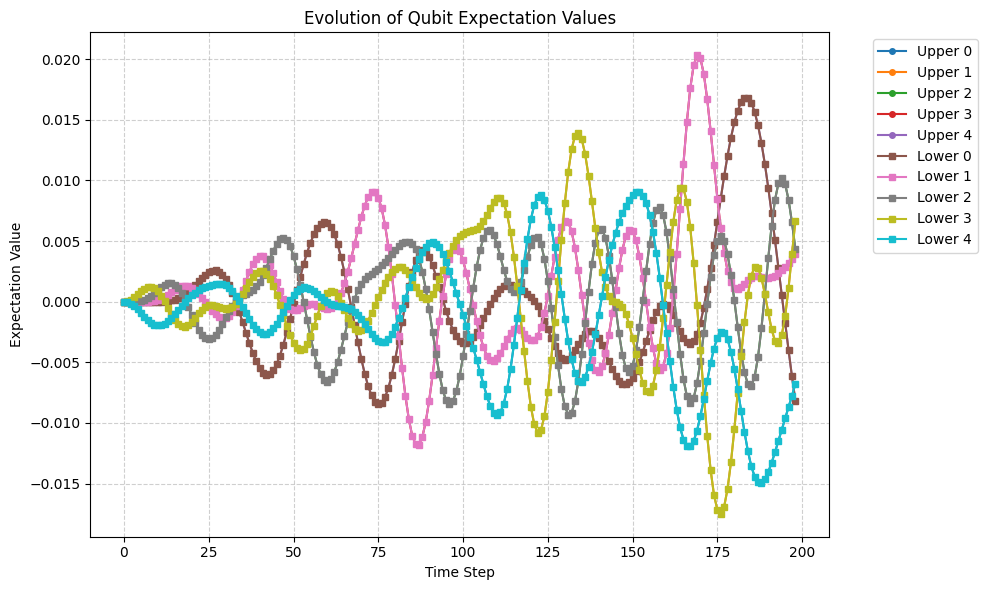

In [3]:
data_array = np.array(expectation_values_qilisdk) - np.array(expectation_values_qutip) 

plt.figure(figsize=(10, 6))

n_qubits = data_array.shape[1]
time_steps = np.arange(data_array.shape[0])

half = n_qubits // 2
for i in range(half):
    plt.plot(time_steps, data_array[:, i], label=f'Upper {i}', marker='o', markersize=4)
for i in range(half, n_qubits):
    plt.plot(time_steps, data_array[:, i], label=f'Lower {i-half}', marker='s', markersize=4)

plt.title('Evolution of Qubit Expectation Values')
plt.xlabel('Time Step')
plt.ylabel('Expectation Value')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()

plt.show()

In [4]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

data_array = np.array(expectation_values_qilisdk) - np.array(expectation_values_qutip) 

plt.figure(figsize=(10, 6))

n_qubits = data_array.shape[1]
time_steps = np.arange(data_array.shape[0])

upper_chain = data_array[:, :chain_length]
lower_chain = data_array[:, chain_length:]

site_indices = np.arange(chain_length)

fig, (ax_up, ax_down) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)

# y_min = float(data_array.min()) - 0.1
# y_max = float(data_array.max()) + 0.1

y_min = -1
y_max = +1

line_up, = ax_up.plot(site_indices, upper_chain[0], marker='o', color='tab:blue')
ax_up.set_ylim(y_min, y_max)
ax_up.set_xticks(site_indices)
ax_up.set_ylabel(r'$\langle Z \rangle$')
ax_up.set_title('Upper chain')
ax_up.grid(True, linestyle='--', alpha=0.6)

line_down, = ax_down.plot(site_indices, lower_chain[0], marker='o', color='tab:red')
ax_down.set_ylim(y_min, y_max)
ax_down.set_xticks(site_indices)
ax_down.set_xlabel('Site index')
ax_down.set_ylabel(r'$\langle Z \rangle$')
ax_down.set_title('Lower chain')
ax_down.grid(True, linestyle='--', alpha=0.6)

time_text = fig.suptitle(f't = {time_steps[0]:.2f}')

stride = 10  # keep 1 of every stride frames
frame_indices = np.arange(0, len(time_steps), stride)

def update(i):
    frame = frame_indices[i]
    line_up.set_ydata(upper_chain[frame])
    line_down.set_ydata(lower_chain[frame])
    time_text.set_text(f't = {time_steps[frame]:.2f}')
    return line_up, line_down, time_text

anim = FuncAnimation(fig, update, frames=len(frame_indices), interval=50, blit=False)

plt.close(fig)
HTML(anim.to_jshtml())


<Figure size 1000x600 with 0 Axes>

In [3]:
import sys, os
sys.path.append(os.path.abspath('..'))

import numpy as np
import matplotlib.pyplot as plt

from models.qutip_model import QutipFermiHubbard
from models.qilisdk_model import QilisdkFermiHubbard

backend = 'qutip'  # 'qutip' or 'qilisdk'

chain_length = 5

gx = 1
gz = 1
e = 0
T = 4.0
dt = 0.01


nsteps = int(T/dt) -1
model_qutip = QutipFermiHubbard(chain_length, gx, gz, e, T, nsteps)

model_qutip.place_single_excitation('up', 3)
model_qutip.place_single_excitation('down', 3)

# model_qutip.place_entangled_pair(0,1)
# model_qutip.place_entangled_pair(2*chain_length-2,2*chain_length-1)

result, expectation_values_qutip = model_qutip.run()


In [8]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

data_array = np.array(expectation_values_qutip) 

plt.figure(figsize=(10, 6))

n_qubits = data_array.shape[1]
time_steps = np.arange(data_array.shape[0])

upper_chain = data_array[:, :chain_length]
lower_chain = data_array[:, chain_length:]

site_indices = np.arange(chain_length)

fig, (ax_up, ax_down) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)

# y_min = float(data_array.min()) - 0.1
# y_max = float(data_array.max()) + 0.1

y_min = -1.1
y_max = +1.1

line_up, = ax_up.plot(site_indices, upper_chain[0], marker='o', color='tab:blue')
ax_up.set_ylim(y_min, y_max)
ax_up.set_xticks(site_indices)
ax_up.set_ylabel(r'$\langle Z \rangle$')
ax_up.set_title('Upper chain')
ax_up.grid(True, linestyle='--', alpha=0.6)

line_down, = ax_down.plot(site_indices, lower_chain[0], marker='o', color='tab:red')
ax_down.set_ylim(y_min, y_max)
ax_down.set_xticks(site_indices)
ax_down.set_xlabel('Site index')
ax_down.set_ylabel(r'$\langle Z \rangle$')
ax_down.set_title('Lower chain')
ax_down.grid(True, linestyle='--', alpha=0.6)

time_text = fig.suptitle(f't = {time_steps[0]:.2f}')

stride = 5 # keep 1 of every stride frames
frame_indices = np.arange(0, len(time_steps), stride)

def update(i):
    frame = frame_indices[i]
    line_up.set_ydata(upper_chain[frame])
    line_down.set_ydata(lower_chain[frame])
    time_text.set_text(f't = {time_steps[frame]:.2f}')
    return line_up, line_down, time_text

anim = FuncAnimation(fig, update, frames=len(frame_indices), interval=50, blit=False)

plt.close(fig)
HTML(anim.to_jshtml())


<Figure size 1000x600 with 0 Axes>

In [7]:
print(len(expectation_values_qutip[0]))

10


In [5]:
entropy = model_qutip.calculate_von_neumann_entropy(result.states)

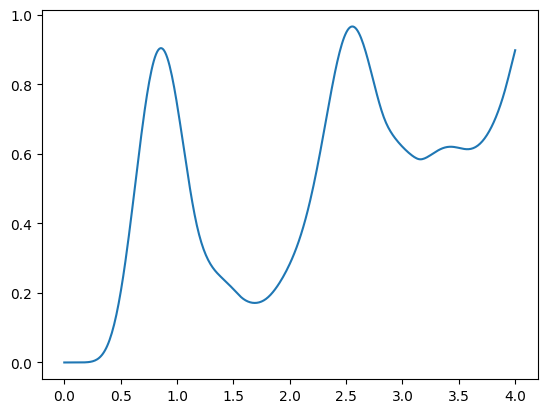

In [6]:
plt.plot(np.linspace(0, T, nsteps), entropy)

In [10]:
import sys, os
sys.path.append(os.path.abspath('..'))

import numpy as np
import matplotlib.pyplot as plt

from models.qutip_model import QutipFermiHubbard
from models.qilisdk_model import QilisdkFermiHubbard

backend = 'qutip'  # 'qutip' or 'qilisdk'

chain_length = 5

gx = 1
e = 0
T = 20.0
dt = 0.01
nsteps = int(T/dt) -1
gz_list = np.linspace(-10, 10, 201)
entropies = []

for gz in gz_list:
    model_qutip = QutipFermiHubbard(chain_length, gx, gz, e, T, nsteps)
    model_qutip.place_single_excitation('up',2)
    model_qutip.place_single_excitation('down',2)

    result, expectation_values_qutip = model_qutip.run()
    entropies.append(model_qutip.calculate_von_neumann_entropy(result.states))

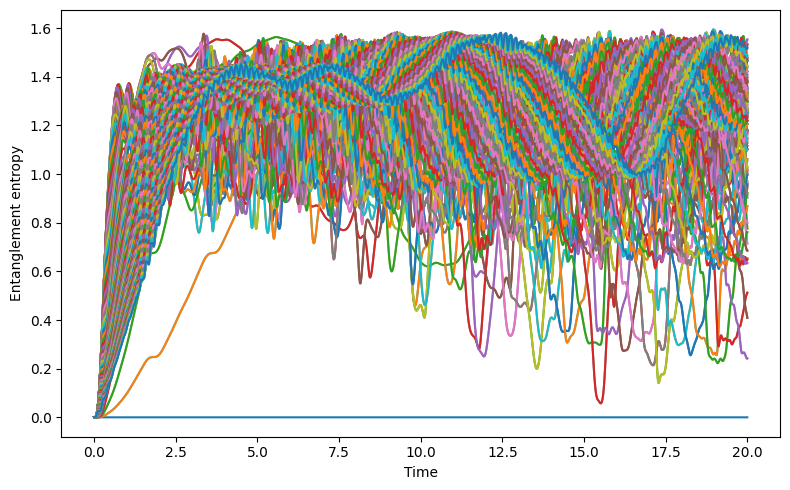

In [11]:
t = np.linspace(0, T, nsteps)


plt.figure(figsize=(8, 5))
for gz, S in zip(gz_list, entropies):
    plt.plot(t, S, label=f'gz={gz:.2f}')
plt.xlabel('Time')
plt.ylabel('Entanglement entropy')
#plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

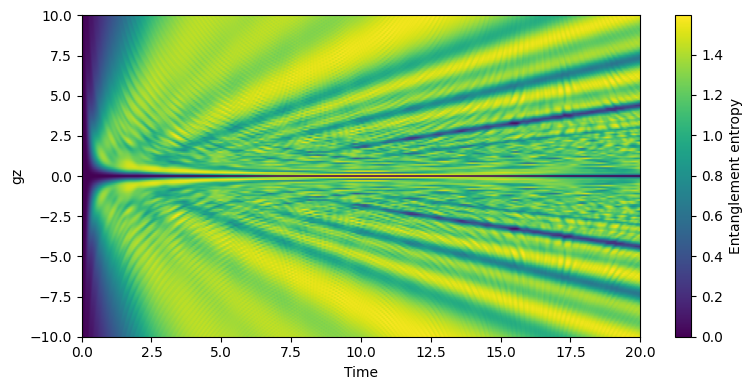

In [12]:
S = np.array(entropies)  # shape: (n_gz, n_time)

plt.figure(figsize=(8, 4))
plt.imshow(S, aspect='auto', origin='lower',
           extent=[t[0], t[-1], gz_list[0], gz_list[-1]])
plt.colorbar(label='Entanglement entropy')
plt.xlabel('Time')
plt.ylabel('gz')
plt.tight_layout()
plt.show()

/var/folders/wh/28dwfv8x0qzfwl1_0pyzvs6h0000gp/T/ipykernel_35918/4274075782.py:15: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  S_final[i, j] = model.calculate_von_neumann_entropy([result.states[-1]])


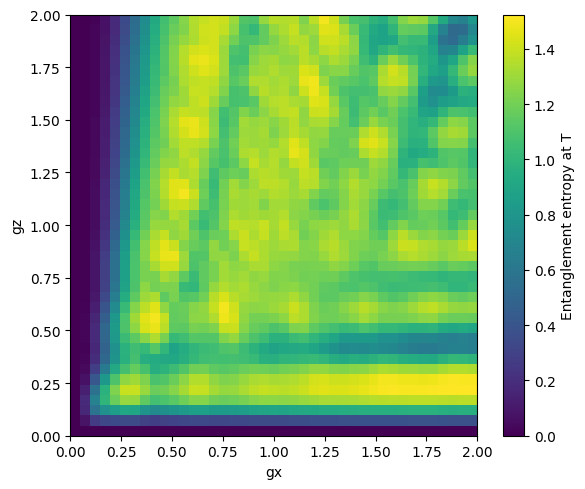

In [ ]:
gx_list = np.linspace(0, 1, 21)
gz_list = np.linspace(0, 1, 21)
T = 5.0
dt = 0.01
nsteps = int(T/dt) - 1

S_final = np.zeros((len(gz_list), len(gx_list)))

for i, gz in enumerate(gz_list):
    for j, gx in enumerate(gx_list):
        model = QutipFermiHubbard(chain_length, gx, gz, e, T, nsteps)
        model.place_single_excitation('up', 0)
        model.place_single_excitation('down', 0)
        result, _ = model.run()
        S_final[i, j] = model.calculate_von_neumann_entropy([result.states[-1]])

plt.figure(figsize=(6, 5))
plt.imshow(S_final, aspect='auto', origin='lower',
           extent=[gx_list[0], gx_list[-1], gz_list[0], gz_list[-1]])
plt.colorbar(label='Entanglement entropy at T')
plt.xlabel('gx')
plt.ylabel('gz')
plt.tight_layout()
plt.show()


In [16]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
chain_length = 5
e=0
gx_list = np.linspace(0, 10, 51)
gz_list = np.linspace(0, 10, 51)
T = 10.0
dt = 0.01
nsteps = int(T/dt) - 1
t = np.linspace(0, T, nsteps)
stride = 1  # animate every stride-th timestep

S = np.zeros((len(t), len(gz_list), len(gx_list)))

for i, gz in enumerate(gz_list):
    for j, gx in enumerate(gx_list):
        model = QutipFermiHubbard(chain_length, gx, gz, e, T, nsteps)
        model.place_single_excitation('up',0)
        model.place_single_excitation('down',chain_length-1)
        result, _ = model.run()
        S[:, i, j] = model.calculate_von_neumann_entropy(result.states)

In [17]:
filename = "0-2N_long_range"
np.save(f"../../experiments/{filename}", S)

In [18]:
S = np.load("../../experiments/0-2N_long_range.npy")

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(S[0], aspect='auto', origin='lower', vmin=S.min(), vmax=S.max(),
               extent=[gx_list[0], gx_list[-1], gz_list[0], gz_list[-1]])
plt.colorbar(im, ax=ax, label='Entanglement entropy')
ax.set_xlabel('gx')
ax.set_ylabel('gz')
title = ax.set_title(f't = {t[0]:.2f}')

def update(k):
    frame = k * stride
    im.set_data(S[frame])
    title.set_text(f't = {t[frame]:.2f}')
    return im, title

frames = len(t) // stride
anim = FuncAnimation(fig, update, frames=frames, interval=50, blit=False)
plt.close(fig)
HTML(anim.to_jshtml())

In [10]:
plus_U = expectation_values_qutip

In [12]:
minus_U = expectation_values_qutip

In [2]:
data_array = np.array(plus_U - minus_U)

upper_chain = data_array[:, :chain_length]
lower_chain = data_array[:, chain_length:]
mirror_diff = upper_chain - lower_chain[:, ::-1]

plt.figure(figsize=(10, 6))

time_steps = np.arange(data_array.shape[0])

for i in range(chain_length):
    plt.plot(time_steps, mirror_diff[:, i], label=f'Upper {i} - Lower {chain_length-1-i}', marker='o', markersize=4)

plt.title('Mirror Difference of Qubit Expectation Values')
plt.xlabel('Time Step')
plt.ylabel('Expectation Value')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.ylim(-1,1)

plt.show()

NameError: name 'plus_U' is not defined

## Next steps

- Add custom observables
- Code domain-wall version
- Plot entanglement entropy
- Make custom architecture version

In [4]:
print(list(range(0,chain_length)))

[0, 1, 2, 3, 4, 5, 6, 7]
